In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://gist.githubusercontent.com/srang992/00185715d41a107fcd60e2ddc93ab6b6/raw/a547170f8ff66b3661c25fee1b660de61af03ddf/netflix_data.csv"
df = pd.read_csv(url)
print("Netflix dataset loaded successfully!")

Netflix dataset loaded successfully!


In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5
Number of columns: 12


In [5]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       5 non-null      str  
 1   type          5 non-null      str  
 2   title         5 non-null      str  
 3   director      2 non-null      str  
 4   cast          3 non-null      str  
 5   country       3 non-null      str  
 6   date_added    5 non-null      str  
 7   release_year  5 non-null      int64
 8   rating        5 non-null      str  
 9   duration      5 non-null      str  
 10  listed_in     5 non-null      str  
 11  description   5 non-null      str  
dtypes: int64(1), str(11)
memory usage: 612.0 bytes


In [6]:
# Display all column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [7]:
# Statistical summary of numerical columns
df.describe()

,release_year
count,5.000000
mean,2020.800000
std,0.447214
min,2020.000000
25%,2021.000000
50%,2021.000000
75%,2021.000000
max,2021.000000


In [8]:
# Count missing values in each column
missing_values = df.isnull().sum()
print("Missing Values:")
print(missing_values)

Missing Values:
show_id         0
type            0
title           0
director        3
cast            2
country         2
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [9]:
# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("Missing Values Percentage:")
print(missing_percentage.round(2))

Missing Values Percentage:
show_id          0.0
type             0.0
title            0.0
director        60.0
cast            40.0
country         40.0
date_added       0.0
release_year     0.0
rating           0.0
duration         0.0
listed_in        0.0
description      0.0
dtype: float64


In [10]:
# Check duplicate records
duplicates = df.duplicated().sum()
print("Number of duplicate records:", duplicates)

Number of duplicate records: 0


In [11]:
# Count Movies and TV Shows
content_counts = df['type'].value_counts()
print(content_counts)

type
TV Show    4
Movie      1
Name: count, dtype: int64


In [12]:
# Calculate content percentages
content_percentage = df['type'].value_counts(normalize=True) * 100
print(content_percentage.round(2))

type
TV Show    80.0
Movie      20.0
Name: proportion, dtype: float64


In [13]:
# Find the top 10 release years
year_counts = df['release_year'].value_counts().head(10)
print(year_counts)

release_year
2021    4
2020    1
Name: count, dtype: int64


In [14]:
# Keep the original dataset safe
netflix = df.copy()
print("Original dataset preserved!")
print("Working dataset shape:", netflix.shape)

Original dataset preserved!
Working dataset shape: (5, 12)


In [15]:
missing = netflix.isnull().sum()
print("Missing values before cleaning:")
print(missing)

Missing values before cleaning:
show_id         0
type            0
title           0
director        3
cast            2
country         2
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [16]:
# Fill missing text values
text_columns = ['director', 'cast', 'country', 'rating',
                'duration', 'date_added']
for col in text_columns:
    netflix[col] = netflix[col].fillna('Unknown')
# Fill missing release years with median
netflix['release_year'] = netflix['release_year'].fillna(
    netflix['release_year'].median()
)
print("Missing values handled successfully!")

Missing values handled successfully!


In [17]:
before = netflix.shape[0]
netflix = netflix.drop_duplicates()
after = netflix.shape[0]
print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Rows before removing duplicates: 5
Rows after removing duplicates: 5
Duplicates removed: 0


In [18]:
print("Missing values after cleaning:")
print(netflix.isnull().sum())
print("\nFinal dataset shape:")
print(netflix.shape)

Missing values after cleaning:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

Final dataset shape:
(5, 12)


In [19]:
country_counts = (
    netflix['country']
    .str.split(',')
    .explode()
    .str.strip()
)

top_countries = country_counts[
    country_counts != 'Unknown'
].value_counts().head(10)

print("Top 10 countries producing Netflix content:")
print(top_countries)

Top 10 countries producing Netflix content:
country
United States    1
South Africa     1
India            1
Name: count, dtype: int64


In [20]:
genre_counts = (
    netflix['listed_in']
    .str.split(',')
    .explode()
    .str.strip()
)

top_genres = genre_counts.value_counts().head(10)

print("Top 10 Netflix genres:")
print(top_genres)

Top 10 Netflix genres:
listed_in
International TV Shows    3
Documentaries             1
TV Dramas                 1
TV Mysteries              1
Crime TV Shows            1
TV Action & Adventure     1
Docuseries                1
Reality TV                1
Romantic TV Shows         1
TV Comedies               1
Name: count, dtype: int64


In [21]:
director_counts = (
    netflix[netflix['director'] != 'Unknown']['director']
    .str.split(',')
    .explode()
    .str.strip()
)

print("Top 10 directors:")
print(director_counts.value_counts().head(10))

Top 10 directors:
director
Kirsten Johnson    1
Julien Leclercq    1
Name: count, dtype: int64


In [22]:
# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print("Visualization style configured successfully!")

Visualization style configured successfully!


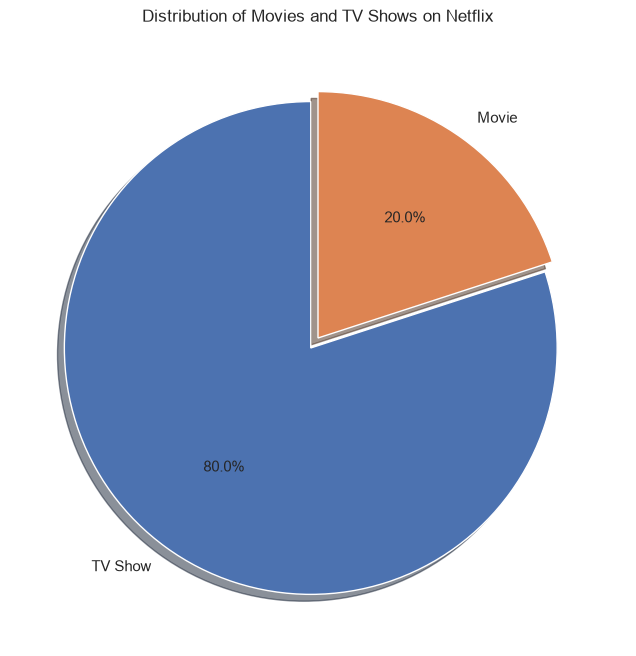

In [23]:
# Count movies and TV shows
content_counts = netflix['type'].value_counts()
# Create pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    content_counts,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.05, 0),
    shadow=True
)

plt.title('Distribution of Movies and TV Shows on Netflix')
plt.show()

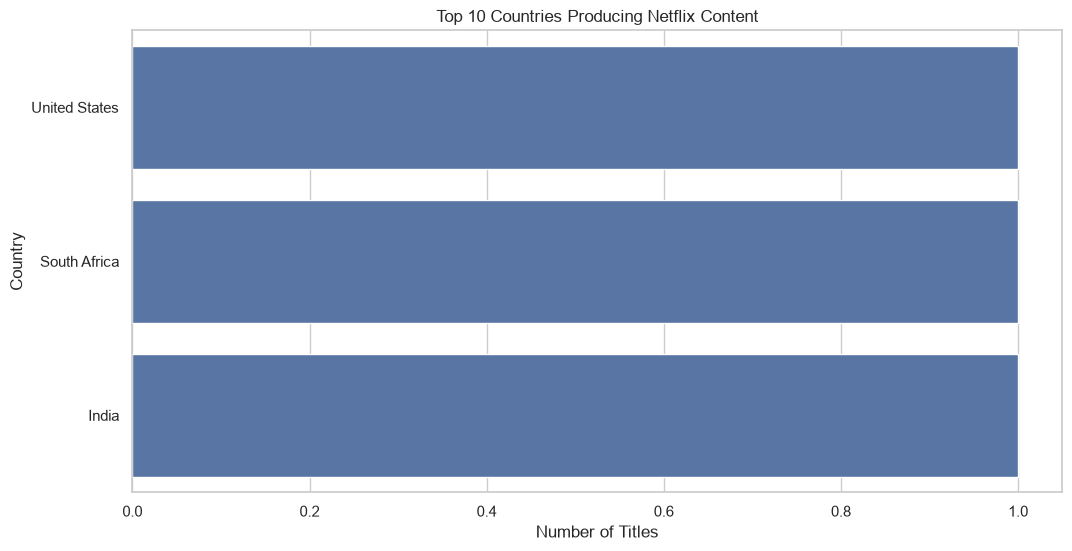

In [24]:
# Get top 10 countries

top_countries = (
    netflix['country']
    .str.split(',')
    .explode()
    .str.strip()
)

top_countries = top_countries[
    top_countries != 'Unknown'
].value_counts().head(10)

# Create bar chart

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

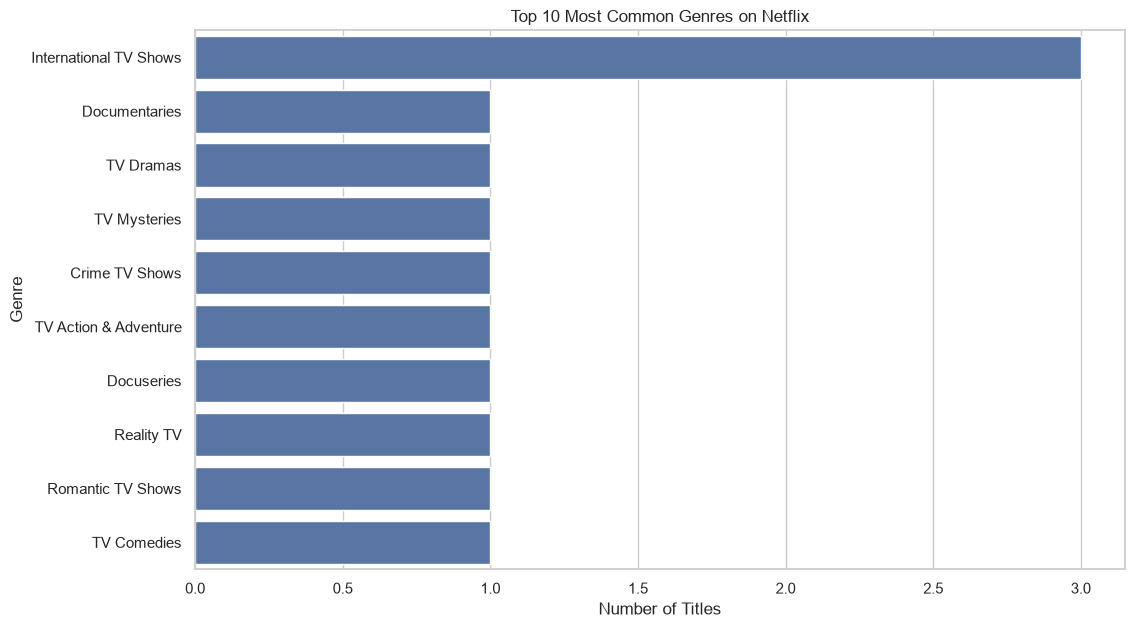

In [25]:
# Get top 10 genres

genre_data = (
    netflix['listed_in']
    .str.split(',')
    .explode()
    .str.strip()
)

top_genres = genre_data.value_counts().head(10)

# Create bar chart

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 10 Most Common Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

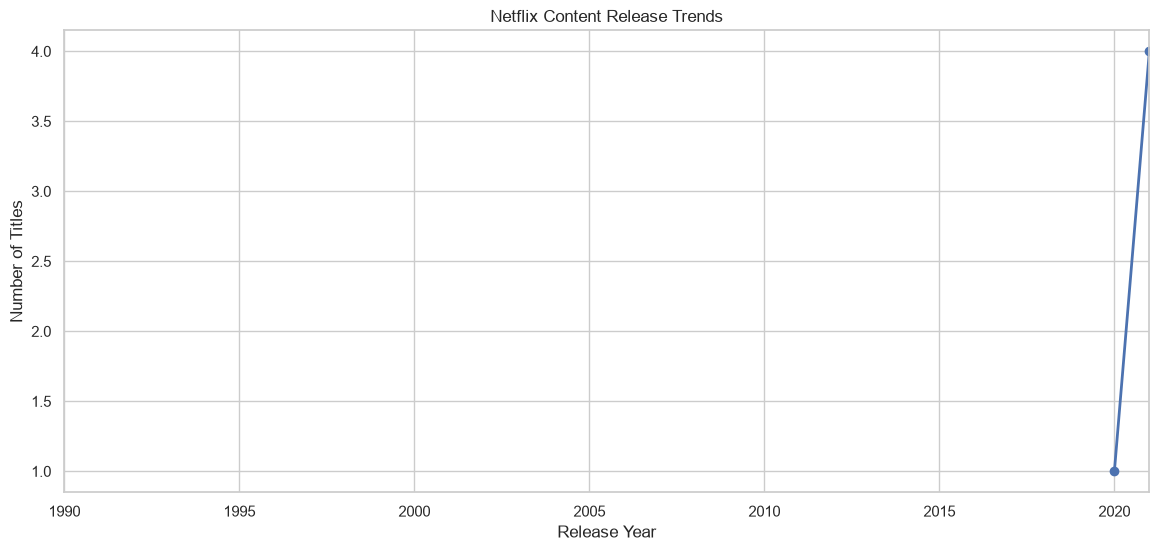

In [26]:
# Count titles by release year

year_data = netflix['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))

plt.plot(
    year_data.index,
    year_data.values,
    marker='o',
    linewidth=2
)

plt.title('Netflix Content Release Trends')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.xlim(1990, year_data.index.max())

plt.grid(True)
plt.show()


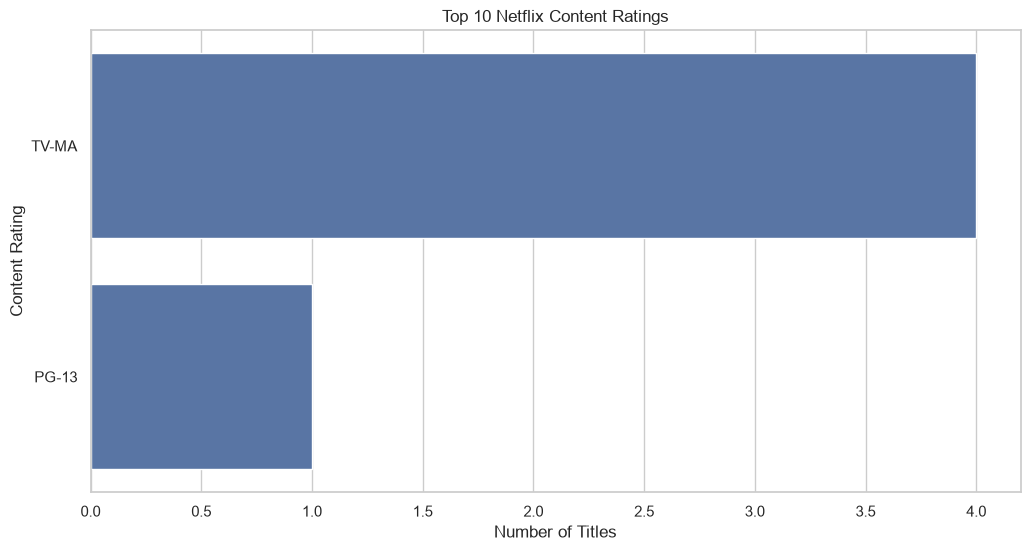

In [27]:
# Count content ratings

rating_counts = (
    netflix['rating']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)

plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Number of Titles')
plt.ylabel('Content Rating')

plt.show()

In [28]:
import os
os.makedirs("charts", exist_ok=True)
print("Charts folder created successfully!")

Charts folder created successfully!


In [31]:
plt.savefig("charts/movies_vs_tvshows.png",dpi=300, bbox_inches='tight')

<Figure size 1000x600 with 0 Axes>

In [32]:
print("=" * 50)
print("       NETFLIX DATA ANALYSIS - KEY FINDINGS")
print("=" * 50)

# 1. Movies vs TV Shows
print("\n1. CONTENT TYPE DISTRIBUTION")
print(netflix['type'].value_counts())

print("\nContent percentages:")
print(
    (netflix['type'].value_counts(normalize=True) * 100)
    .round(2)
)

# 2. Top countries
print("\n2. TOP 5 COUNTRIES")
print(top_countries.head(5))

# 3. Top genres
print("\n3. TOP 5 GENRES")
print(top_genres.head(5))

# 4. Most frequent release years
print("\n4. TOP 5 RELEASE YEARS")
print(
    df['release_year']
    .dropna()
    .value_counts()
    .head(5)
)

# 5. Top content ratings
print("\n5. TOP 5 CONTENT RATINGS")
print(rating_counts.head(5))

print("\n" + "=" * 50)
print("ANALYSIS COMPLETED!")
print("=" * 50)

       NETFLIX DATA ANALYSIS - KEY FINDINGS

1. CONTENT TYPE DISTRIBUTION
type
TV Show    4
Movie      1
Name: count, dtype: int64

Content percentages:
type
TV Show    80.0
Movie      20.0
Name: proportion, dtype: float64

2. TOP 5 COUNTRIES
country
United States    1
South Africa     1
India            1
Name: count, dtype: int64

3. TOP 5 GENRES
listed_in
International TV Shows    3
Documentaries             1
TV Dramas                 1
TV Mysteries              1
Crime TV Shows            1
Name: count, dtype: int64

4. TOP 5 RELEASE YEARS
release_year
2021    4
2020    1
Name: count, dtype: int64

5. TOP 5 CONTENT RATINGS
rating
TV-MA    4
PG-13    1
Name: count, dtype: int64

ANALYSIS COMPLETED!


In [ ]:
Conclusion
This project explored the Netflix Movies and TV Shows dataset using Python.
The analysis examined content distribution, production countries, genres, release years, and content ratings.
The exploratory data analysis helped identify missing values, inspect data types, and understand patterns within the dataset.
The visualizations provided a clear representation of Netflix's content distribution and release trends.
The project demonstrates how Python libraries such as Pandas, Matplotlib, and Seaborn can be used to analyze datasets and communicate meaningful insights.

Future Scope:
- Perform sentiment analysis on Netflix reviews.
- Analyze audience preferences.
- Explore trends in content addition over time.
- Build an interactive Netflix analytics dashboard.

In [33]:
import os

os.makedirs("charts", exist_ok=True)

# Chart 1: Movies vs TV Shows
plt.figure(figsize=(8, 8))
plt.pie(
    content_counts,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Movies vs TV Shows")
plt.savefig("charts/01_content_distribution.png", dpi=300,
            bbox_inches="tight")
plt.close()

# Chart 2: Top Countries
plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Netflix Countries")
plt.savefig("charts/02_top_countries.png", dpi=300,
            bbox_inches="tight")
plt.close()

# Chart 3: Top Genres
plt.figure(figsize=(12, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Netflix Genres")
plt.savefig("charts/03_top_genres.png", dpi=300,
            bbox_inches="tight")
plt.close()

# Chart 4: Release Trends
year_data = (
    df['release_year'].dropna()
    .astype(int).value_counts().sort_index()
)

plt.figure(figsize=(14, 6))
plt.plot(year_data.index, year_data.values, marker='o')
plt.title("Netflix Content Release Trends")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.savefig("charts/04_release_trends.png", dpi=300,
            bbox_inches="tight")
plt.close()

# Chart 5: Content Ratings
plt.figure(figsize=(12, 6))
sns.barplot(x=rating_counts.values, y=rating_counts.index)
plt.title("Netflix Content Ratings")
plt.savefig("charts/05_content_ratings.png", dpi=300,
            bbox_inches="tight")
plt.close()

print("All five charts saved successfully!")

All five charts saved successfully!
